# Predicting Carbon Monoxide Concentration from Low-Cost Gas Sensors

**Project type:** Supervised regression  
**Dataset:** UCI Air Quality  
**Target:** `CO(GT)` — reference-analyser Carbon Monoxide concentration  
**Objective:** Estimate Carbon Monoxide concentration using low-cost sensor readings and meteorological variables.

## Project workflow

- Load and inspect the raw data.
- Clean invalid and missing values.
- Explore the target, features, and time patterns.
- Define a chronological train/test split.
- Establish a dummy baseline.
- Train and compare regression models using preprocessing pipelines.
- Inspect errors, feature importance, and a feature-ablation experiment.
- Record limitations and next steps.

## 1. Environment setup and imports

Keep imports, configuration, and project paths together near the beginning. This makes dependencies visible and avoids importing the same library in multiple sections.

In [20]:
# Standard library
from pathlib import Path

# Third-party libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: preprocessing, models, and evaluation
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reproducibility and display configuration
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

### Project paths

Expected project layout:

```text
ml-demos/
│
├── data/
│   └── air_quality/
│       ├── raw/
│       │   └── AirQualityUCI.csv
│       │
│       └── cleaned/
│
├── models/
│
└── notebooks/
    └── CarbonMonoxide_analysis.ipynb
```

Place the original UCI CSV in `data/air_quality/raw/`. Running the notebook from the project root or its `notebooks/` directory is supported.

In [21]:
# Define the current working directory
CURRENT_DIR = Path.cwd()

# Navigate to the project root directory
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

# Define the path to the raw data file
RAW_DATA_PATH = PROJECT_ROOT/"data"/"air_quality"/"raw"/"AirQualityUCI.csv"

# Cleaned data path
CLEANED_DATA_PATH = PROJECT_ROOT/"data"/"air_quality"/"cleaned"

# Create the cleaned data directory if it doesn't exist
CLEANED_DATA_PATH.mkdir(parents=True, exist_ok=True)

# Validate input path
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Raw data file not found at {RAW_DATA_PATH}. Please ensure the dataset is downloaded and placed in the correct directory.")

#print("Current working directory:", CURRENT_DIR)
#print("Project root directory:", PROJECT_ROOT)
#print("Raw data path:", RAW_DATA_PATH)
#print("Cleaned data path:", CLEANED_DATA_PATH)

## 2. Load and inspect the data

The source file uses semicolons as field separators and commas as decimal separators.

In [22]:
aq_raw = pd.read_csv(RAW_DATA_PATH, sep=";", decimal=",")

print(f"Raw shape: {aq_raw.shape}")
display(aq_raw)
display(aq_raw.dtypes.to_frame("data_type"))

Raw shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,data_type
Date,str
Time,str
CO(GT),float64
PT08.S1(CO),float64
NMHC(GT),float64
C6H6(GT),float64
PT08.S2(NMHC),float64
NOx(GT),float64
PT08.S3(NOx),float64
NO2(GT),float64


In [23]:
# Inspect fully empty rows and columns before removing them.
fully_empty_rows = aq_raw.isna().all(axis=1).sum()
fully_empty_columns = aq_raw.columns[aq_raw.isna().all(axis=0)].tolist()

print(f"Fully empty rows: {fully_empty_rows}")
print(f"Fully empty columns: {fully_empty_columns}")

Fully empty rows: 114
Fully empty columns: ['Unnamed: 15', 'Unnamed: 16']


## 3. Data cleaning and timestamp preparation

The dataset uses `-200` as a marker for missing measurements. Converting this marker to `NaN` before calculating missing-value statistics or training models is required.

Removal of rows and columns that are entirely empty. The `NMHC(GT)` reference-analyser column has extensive missingness and is not part of the selected feature set, so it is excluded from this experiment.

Rows with a missing target cannot be used for supervised training or evaluation. Missing feature values are retained for now and will be imputed inside model pipelines. However, it's better to remove rows that have has missing values across all features.

In [24]:
aq = aq_raw.copy()

# Convert the dataset's missing-value markers to NaN.
aq = aq.replace(-200, np.nan)

# Remove completely empty rows and columns.
aq = aq.dropna(axis=0, how="all")
aq = aq.dropna(axis=1, how="all")
display(aq.describe())
display((aq.isnull().mean()*100).round(2).sort_values(ascending=False).to_frame("missing_percentage"))

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,7674.000000,8991.000000,914.000000,8991.000000,8991.000000,7718.000000,8991.000000,7715.000000,8991.000000,8991.000000,8991.000000,8991.000000,8991.000000
mean,2.152750,1099.833166,218.811816,10.083105,939.153376,246.896735,835.493605,113.091251,1456.264598,1022.906128,18.317829,49.234201,1.025530
std,1.453252,217.080037,204.459921,7.449820,266.831429,212.979168,256.817320,48.370108,346.206794,398.484288,8.832116,17.316892,0.403813
min,0.100000,647.000000,7.000000,0.100000,383.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700
25%,1.100000,937.000000,67.000000,4.400000,734.500000,98.000000,658.000000,78.000000,1227.000000,731.500000,11.800000,35.800000,0.736800
50%,1.800000,1063.000000,150.000000,8.200000,909.000000,180.000000,806.000000,109.000000,1463.000000,963.000000,17.800000,49.600000,0.995400
75%,2.900000,1231.000000,297.000000,14.000000,1116.000000,326.000000,969.500000,142.000000,1674.000000,1273.500000,24.400000,62.500000,1.313700
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


,missing_percentage
NMHC(GT),90.23
CO(GT),17.99
NO2(GT),17.55
NOx(GT),17.52
PT08.S2(NMHC),3.91
C6H6(GT),3.91
PT08.S1(CO),3.91
PT08.S5(O3),3.91
T,3.91
PT08.S3(NOx),3.91


In [25]:
# This reference-analyser column is missing 90 percent of values, it will not be used in the selected modelling task.
aq = aq.drop(columns=["NMHC(GT)"])

print(f"Shape after removing fully empty rows/columns and NMHC(GT): {aq.shape}")
display(aq.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

Shape after removing fully empty rows/columns and NMHC(GT): (9357, 14)


,missing_values
CO(GT),1683
NO2(GT),1642
NOx(GT),1639
PT08.S2(NMHC),366
C6H6(GT),366
PT08.S1(CO),366
PT08.S5(O3),366
T,366
PT08.S3(NOx),366
PT08.S4(NO2),366


In [26]:
# Remove rows where the supervised target is unavailable.
target = "CO(GT)"
missing_target_count = aq[target].isna().sum()

aq = aq.dropna(subset=[target]).copy()

print(f"Rows removed because target was missing values: {missing_target_count}")
print(f"Rows available after target filtering: {len(aq)}")

Rows removed because target was missing values: 1683
Rows available after target filtering: 7674


### Convert `Date` and `Time` into a timestamp

A chronological split requires correctly ordered observations. Combine the two source columns into a pandas datetime index, remove the original text columns, and sort explicitly.

In [27]:
timestamp = pd.to_datetime(
    aq["Date"] + " " + aq["Time"],
    format="%d/%m/%Y %H.%M.%S",
    errors="raise"
)

aq = aq.drop(columns=["Date", "Time"])
aq.index = timestamp
aq.index.name = "Timestamp"
aq = aq.sort_index()

print(f"Date range: {aq.index.min()} to {aq.index.max()}")
print(f"Duplicate timestamps: {aq.index.duplicated().sum()}")

Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Duplicate timestamps: 0


In [28]:
# Inspect sampling intervals and gaps.
time_gaps = aq.index.to_series().diff()

display(time_gaps.value_counts().head(10).to_frame("interval_count"))
print(f"Largest gap: {time_gaps.max()}")

,interval_count
Timestamp,
0 days 01:00:00,7486
0 days 02:00:00,145
0 days 03:00:00,9
0 days 05:00:00,4
2 days 07:00:00,2
0 days 20:00:00,2
2 days 01:00:00,1
0 days 21:00:00,1
6 days 03:00:00,1


Largest gap: 7 days 06:00:00


**Interpretation:** Most observations are hourly, but there are some gaps. A row-wise model can still be trained on the available observations, but gaps matter for lag-based features, rolling windows, and time-series validation. Those approaches would need explicit handling of missing time intervals.

## 4. Exploratory data analysis

EDA helps understand the target distribution, missingness, time patterns, and relationships between the features or the candidate predictors and the target. These observations help in modelling choices.

In [29]:
display(aq.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
CO(GT),7674.0,2.15,1.45,0.10,1.10,1.80,2.90,11.90
PT08.S1(CO),7344.0,1110.58,218.68,647.00,946.00,1075.00,1246.00,2040.00
C6H6(GT),7344.0,10.28,7.44,0.20,4.60,8.50,14.30,63.70
PT08.S2(NMHC),7344.0,947.20,265.47,387.00,743.00,919.00,1125.25,2214.00
NOx(GT),7261.0,255.31,215.35,2.00,103.00,188.00,339.00,1479.00
PT08.S3(NOx),7344.0,826.92,256.65,322.00,649.00,795.00,960.00,2683.00
NO2(GT),7258.0,114.81,48.24,2.00,80.00,110.00,144.00,340.00
PT08.S4(NO2),7344.0,1444.75,350.34,551.00,1203.00,1447.00,1673.00,2775.00
PT08.S5(O3),7344.0,1043.51,405.57,221.00,744.75,990.00,1305.00,2523.00
T,7344.0,17.77,8.86,-1.90,11.20,16.90,23.80,44.60


### Missingness after target filtering

In [30]:
missing_summary = pd.DataFrame({
    "missing_count": aq.isna().sum(),
    "missing_percent": (aq.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

,missing_count,missing_percent
NO2(GT),416,5.42
NOx(GT),413,5.38
PT08.S1(CO),330,4.30
C6H6(GT),330,4.30
PT08.S5(O3),330,4.30
PT08.S2(NMHC),330,4.30
PT08.S3(NOx),330,4.30
PT08.S4(NO2),330,4.30
RH,330,4.30
T,330,4.30


### Target distribution

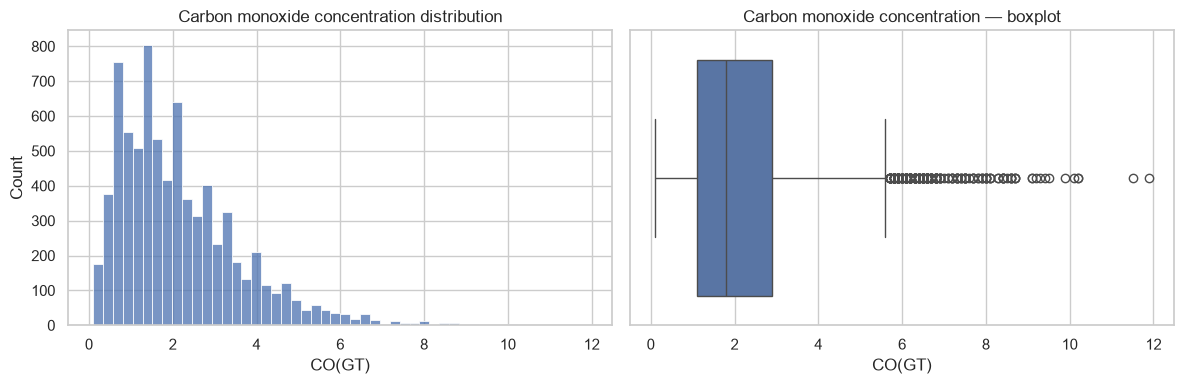

Skew:   1.37
Mean:   2.15
Median: 1.80
Range:  0.10 to 11.90


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(aq[target], bins=50, ax=axes[0])
axes[0].set_title("Carbon monoxide concentration distribution")
axes[0].set_xlabel("CO(GT)")

sns.boxplot(x=aq[target], ax=axes[1])
axes[1].set_title("Carbon monoxide concentration — boxplot")
axes[1].set_xlabel("CO(GT)")

plt.tight_layout()
plt.show()

print(f"Skew:   {aq[target].skew():.2f}")
print(f"Mean:   {aq[target].mean():.2f}")
print(f"Median: {aq[target].median():.2f}")
print(f"Range:  {aq[target].min():.2f} to {aq[target].max():.2f}")

### Feature distributions

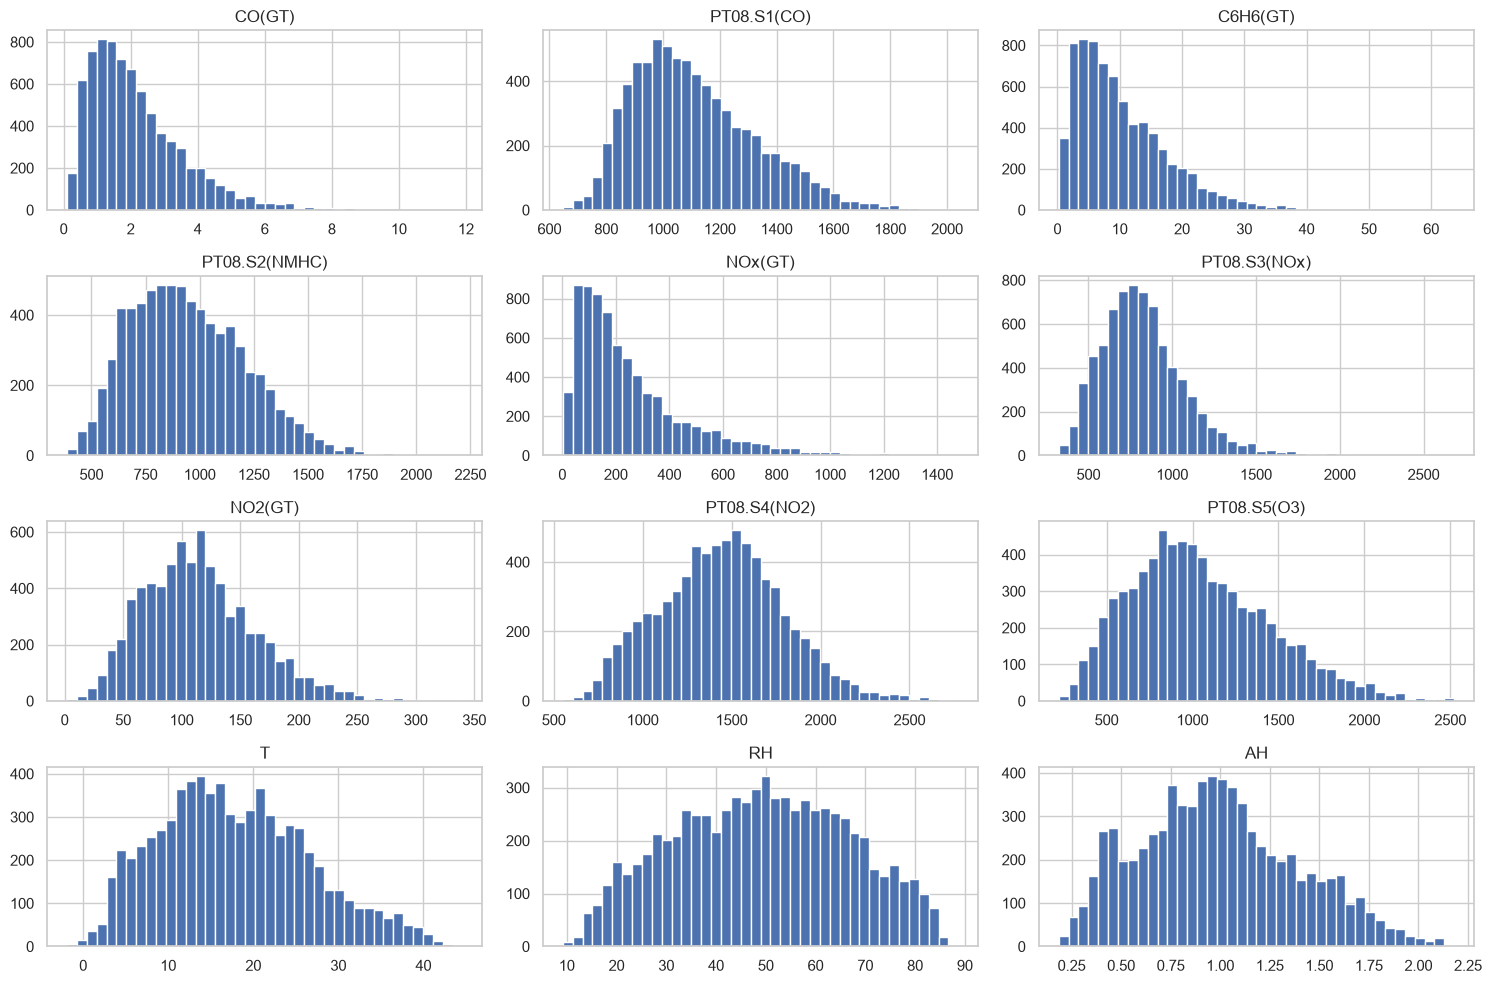

In [32]:
aq.hist(bins=40, figsize=(15, 10))
plt.tight_layout()
plt.show()

### Target over time

Since the dataset contains around 9000 hourly points, it would be easier to analyse the Carbon Monoxide distribution on a day basis.

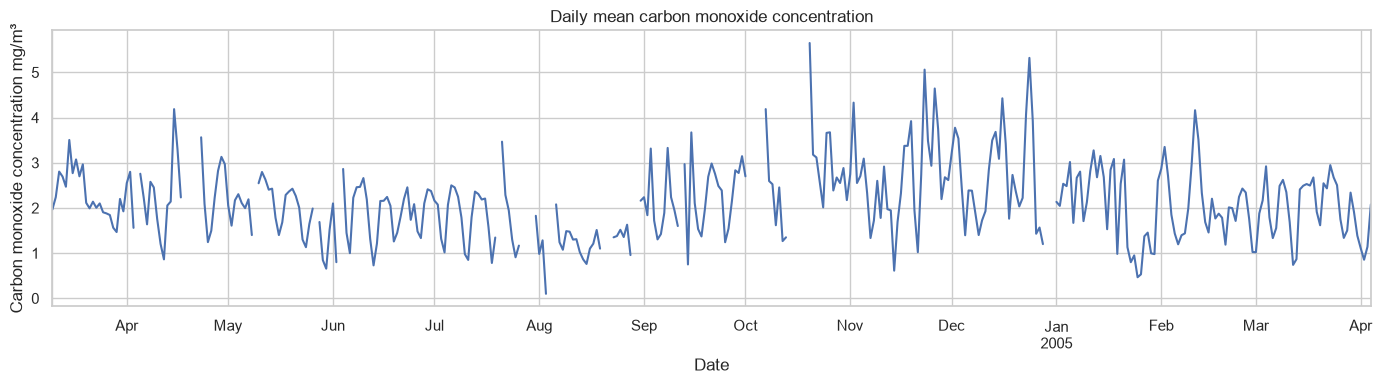

In [33]:
daily_target = aq[target].resample("D").mean()

ax = daily_target.plot(figsize=(14, 4), title="Daily mean carbon monoxide concentration")
ax.set_ylabel("Carbon monoxide concentration mg/m³")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()

### Average target by hour of day

Distribution of hourly Carbon Monoxide concentration averaged across all the days in the dataset.

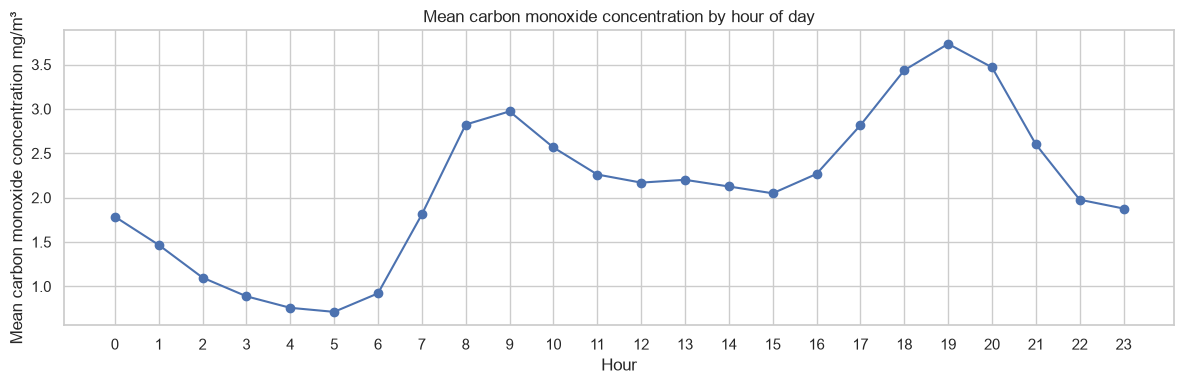

In [34]:
hourly_target = aq.groupby(aq.index.hour)[target].mean()

ax = hourly_target.plot(figsize=(12, 4), marker="o")
ax.set_title("Mean carbon monoxide concentration by hour of day")
ax.set_xlabel("Hour")
ax.set_ylabel("Mean carbon monoxide concentration mg/m³")
ax.set_xticks(range(24))
plt.tight_layout()
plt.show()

## 5. Define the modelling problem

The objective is to estimate reference-analyser Carbon Monoxide concentration from the five low-cost sensor channels and three meteorological variables.

The columns ending in `(GT)` are reference-analyser measurements. They are excluded from the predictors to avoid using other reference-analyser readings as inputs to a low-cost-sensor model.

In [35]:
features = [
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH",
]

print(f"Number of observations: {len(aq[features])}")
print(f"Number of features: {len(features)}")
print(f"Target: {target}")
print(f"Missing feature values: {aq[features].isna().sum()}")


Number of observations: 7674
Number of features: 8
Target: CO(GT)
Missing feature values: PT08.S1(CO)      330
PT08.S2(NMHC)    330
PT08.S3(NOx)     330
PT08.S4(NO2)     330
PT08.S5(O3)      330
T                330
RH               330
AH               330
dtype: int64


In [36]:
fully_empty_feature_rows= aq[features].isna().all(axis=1)
print(f"Fully empty feature rows to be removed: {fully_empty_feature_rows.sum()}")
aq=aq[~fully_empty_feature_rows].copy()

X = aq[features].copy()
Y = aq[target].copy()

print(f"Missing feature values after removing rows with no data: {X.isna().sum()}")

Fully empty feature rows to be removed: 330
Missing feature values after removing rows with no data: PT08.S1(CO)      0
PT08.S2(NMHC)    0
PT08.S3(NOx)     0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64


### Feature-target relationships

Correlation and scatter plots can reveal strong associations, nonlinear patterns, and possible explanations about model performance.

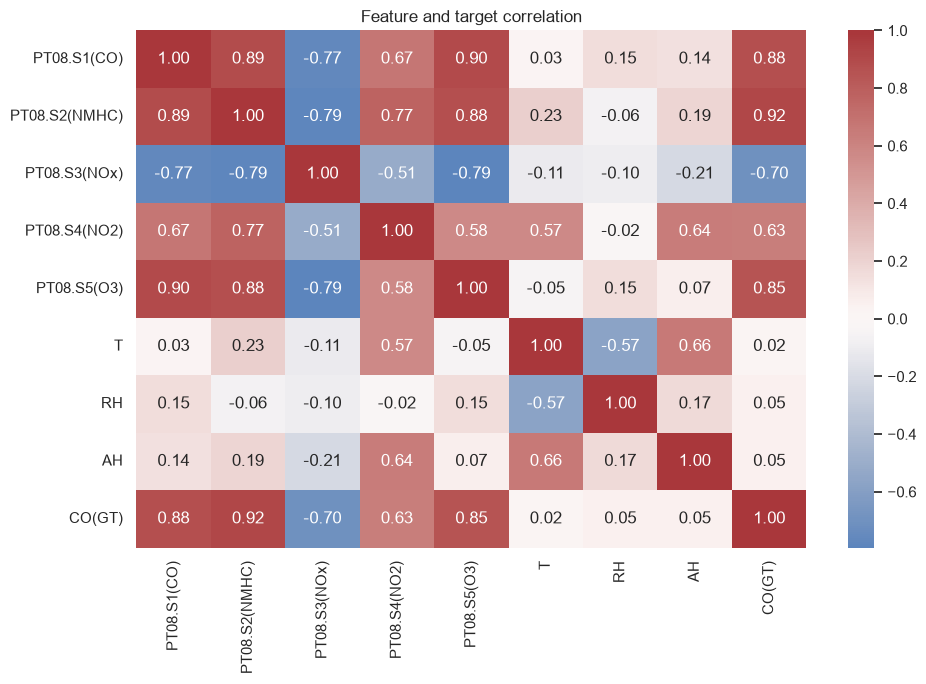

,correlation_with_target
PT08.S2(NMHC),0.915514
PT08.S1(CO),0.879288
PT08.S5(O3),0.854182
PT08.S4(NO2),0.630703
RH,0.048890
AH,0.048556
T,0.022109
PT08.S3(NOx),-0.703446


In [37]:
correlation = aq[features + [target]].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Feature and target correlation")
plt.tight_layout()
plt.show()

display(correlation[target].drop(target).sort_values(ascending=False).to_frame("correlation_with_target"))

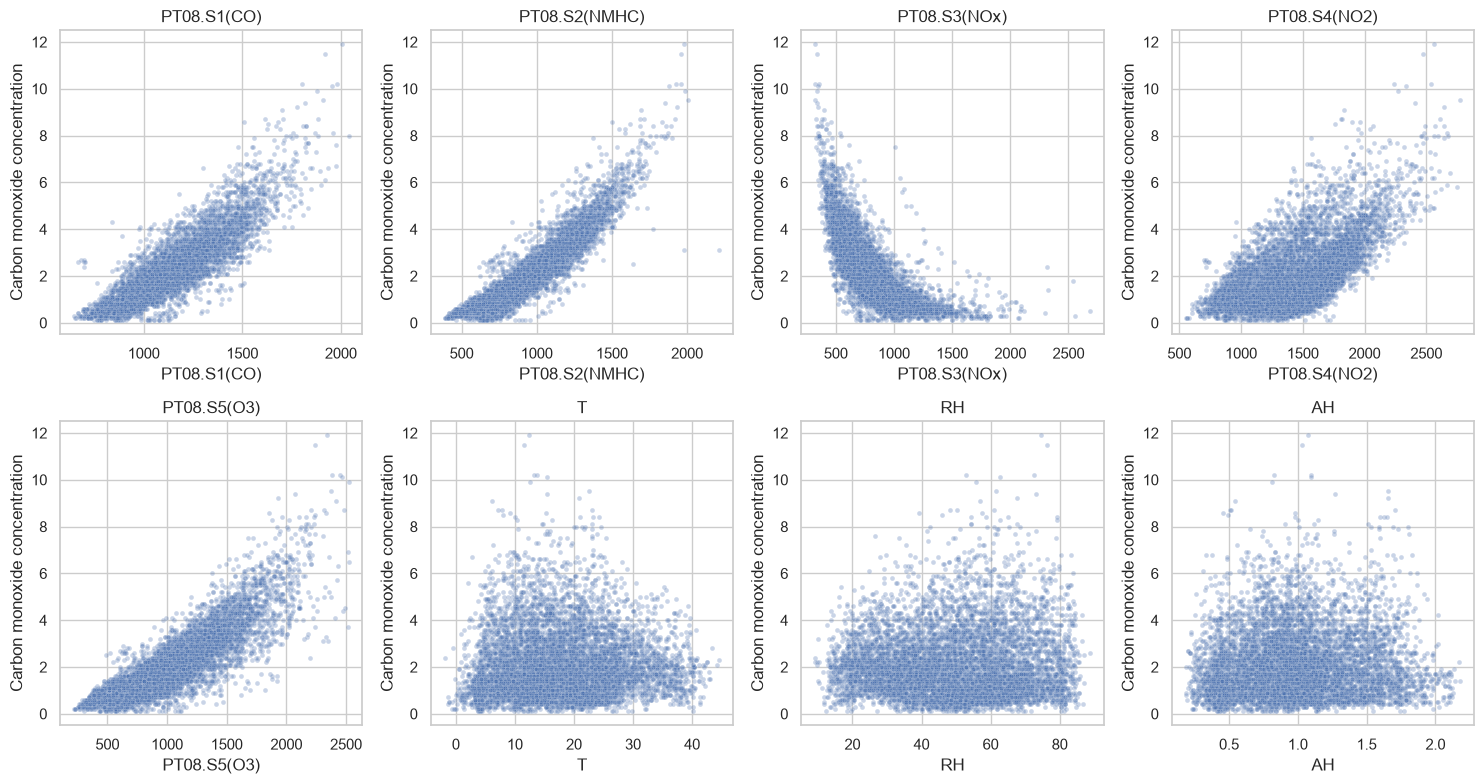

In [38]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for feature, ax in zip(features, axes.flat):
    sns.scatterplot(data=aq, x=feature, y=target, s=12, alpha=0.3, ax=ax)
    ax.set_title(feature)
    ax.set_ylabel("Carbon monoxide concentration")

plt.tight_layout()
plt.show()

## 6. Chronological train/test split

The intended use is to predict observations occurring after the data used for training. Therefore, split chronologically rather than randomly.

A random split might put very similar observations in both the training and test sets. Splitting the data by time gives a more realistic first test of how well the model predicts future data. However, it uses only one time period, so it cannot show how well the model performs in other years or locations.


In [39]:
split_position = int(len(X) * 0.80)

X_train = X.iloc[:split_position].copy()
X_test = X.iloc[split_position:].copy()
Y_train = Y.iloc[:split_position].copy()
Y_test = Y.iloc[split_position:].copy()

print(
    f"Train period: {X_train.index.min()} to {X_train.index.max()} "
    f"({len(X_train):,} rows)"
)
print(
    f"Test period:  {X_test.index.min()} to {X_test.index.max()} "
    f"({len(X_test):,} rows)"
)
print(f"Training shape: {X_train.shape}; target shape: {Y_train.shape}")
print(f"Test shape:     {X_test.shape}; target shape: {Y_test.shape}")

Train period: 2004-03-10 18:00:00 to 2005-01-28 11:00:00 (5,875 rows)
Test period:  2005-01-28 12:00:00 to 2005-04-04 14:00:00 (1,469 rows)
Training shape: (5875, 8); target shape: (5875,)
Test shape:     (1469, 8); target shape: (1469,)


## 7. Establish a dummy baseline

A dummy regressor ignores the input features and predicts a simple statistic from the training target. Any useful model should improve on this baseline under the same test split and metrics.

The baseline helps interpret the model scores and can reveal problems with feature alignment or evaluation.

In [40]:
def regression_metrics(Y_true, Y_pred):
    """Return a consistent set of regression metrics."""
    return {
        "MAE": mean_absolute_error(Y_true, Y_pred),
        "RMSE": mean_squared_error(Y_true, Y_pred) ** 0.5,
        "R2": r2_score(Y_true, Y_pred),
    }

baseline_rows = {}

for strategy in ("mean", "median"):
    baseline = DummyRegressor(strategy=strategy)
    baseline.fit(X_train, Y_train)
    baseline_predictions = baseline.predict(X_test)
    baseline_rows[f"Dummy ({strategy})"] = regression_metrics(Y_test, baseline_predictions)

baseline_results = pd.DataFrame(baseline_rows).T
display(baseline_results.round(3))

,MAE,RMSE,R2
Dummy (mean),1.068,1.320,-0.030
Dummy (median),1.000,1.301,-0.001


## 8. Train and compare regression models

Use scikit-learn pipelines to keep preprocessing attached to each model. `SimpleImputer` learns column medians from the training data during `.fit()` and applies those same values to later data during `.predict()`.

This prevents the test set from influencing the imputation statistics and makes the preprocessing reusable at inference time.

However, rows where every feature is missing (the cheap sensors were offline) are dropped, because a model cannot predict from no inputs. After that, no feature values are missing, so the `SimpleImputer` in the pipelines changes nothing here; it stays as a precaitionary measure.

In [41]:
model_pipelines = {
    "Linear regression": make_pipeline(
        SimpleImputer(strategy="median"),
        LinearRegression()
    ),
    "Decision tree (depth 6)": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE)
    ),
    "Random forest (200 trees)": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ),
}

In [42]:
model_predictions = {}
model_results = {}

for model_name, pipeline in model_pipelines.items():
    pipeline.fit(X_train, Y_train)
    predictions = pipeline.predict(X_test)

    model_predictions[model_name] = predictions
    model_results[model_name] = regression_metrics(Y_test, predictions)

model_results_df = pd.DataFrame(model_results).T.sort_values("R2", ascending=False)
display(model_results_df.round(3))

,MAE,RMSE,R2
Linear regression,0.344,0.484,0.862
Random forest (200 trees),0.368,0.538,0.829
Decision tree (depth 6),0.411,0.642,0.756


### Compare models with the dummy baseline

Review MAE, RMSE, and R² together. MAE and RMSE are in the target's units; RMSE penalizes large errors more strongly. R² measures performance relative to predicting the test-set mean and can be negative.

In [43]:
all_results = pd.concat([baseline_results, model_results_df])
display(all_results.round(3))

,MAE,RMSE,R2
Dummy (mean),1.068,1.320,-0.030
Dummy (median),1.000,1.301,-0.001
Linear regression,0.344,0.484,0.862
Random forest (200 trees),0.368,0.538,0.829
Decision tree (depth 6),0.411,0.642,0.756


## 9. Error analysis

A single metric does not show where a model performs poorly. Inspect predicted-versus-observed values and residuals for the two leading models, linear regression and the random forest. This helps identify systematic bias, extreme errors, and regions where performance deteriorates.

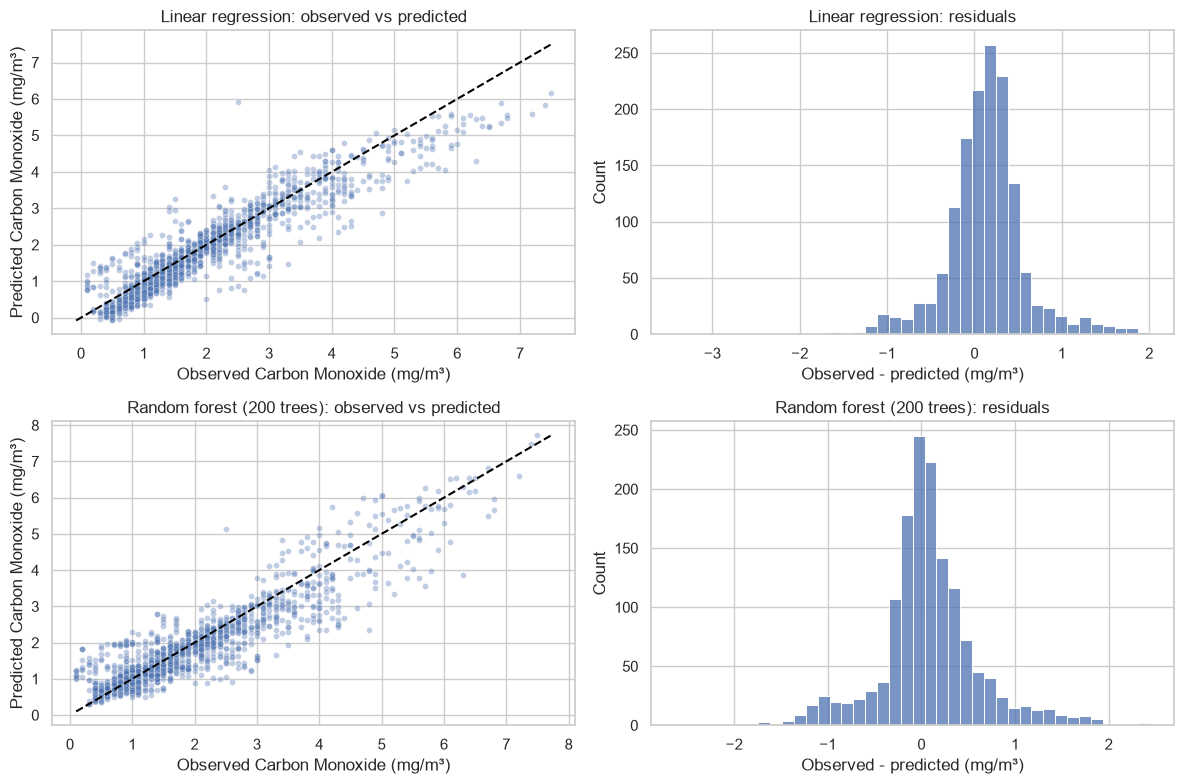

In [44]:
compare = ["Linear regression", "Random forest (200 trees)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, name in zip(axes, compare):
    pred = model_predictions[name]
    resid = Y_test - pred

    # Left: observed vs predicted
    sns.scatterplot(x=Y_test, y=pred, alpha=0.35, s=18, ax=row[0])
    lim = [min(Y_test.min(), pred.min()), max(Y_test.max(), pred.max())]
    row[0].plot(lim, lim, "--", color="black")
    row[0].set(title=f"{name}: observed vs predicted",
               xlabel="Observed Carbon Monoxide (mg/m³)", ylabel="Predicted Carbon Monoxide (mg/m³)")

    # Right: how big and how spread out the mistakes are
    sns.histplot(resid, bins=40, ax=row[1])
    row[1].set(title=f"{name}: residuals",
               xlabel="Observed - predicted (mg/m³)")

plt.tight_layout()
plt.show()

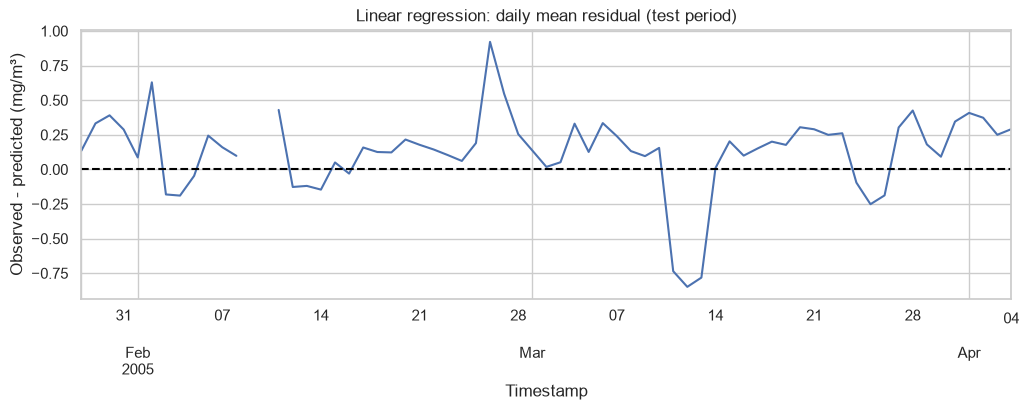

In [45]:
resid_linear = Y_test - model_predictions["Linear regression"]

resid_linear.resample("D").mean().plot(
    figsize=(12, 3.5),
    title="Linear regression: daily mean residual (test period)"
)
plt.axhline(0, color="black", ls="--")
plt.ylabel("Observed - predicted (mg/m³)")
plt.show()

## 10. Inspect feature importance and test the dominant-feature hypothesis

The original exploratory analysis suggested that `PT08.S2(NMHC)`, `PT08.S1(C)`, and `PT08.S5(O3)` are strongly associated with Carbon Monoxide `CO(GT)`.

The main evidence is a feature ablation: the same linear regression is trained on different subsets of the features and scored on the same chronological test set. This shows how much each group of sensors contributes.

As a cross-check, the random forest's feature importance is also shown. It should be read with care: importance is shared among correlated sensors (S1, S2 and S5 move together), so a low score for one sensor does not mean it carries no information, and it is not causal.

In [46]:
feature_sets = {
    "All features": features,
    "S2 only": ["PT08.S2(NMHC)"],
    "S1 only (the CO sensor)": ["PT08.S1(CO)"],
    "S1 + S5 (no S2)": ["PT08.S1(CO)", "PT08.S5(O3)"],
    "S1 + S2 + S5": ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S5(O3)"],
    "Weather only (T, RH, AH)": ["T", "RH", "AH"],
    "All sensors, no weather": ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)", "PT08.S5(O3)"],
}

ablation = {}
for exp_name, cols in feature_sets.items():
    model_pipelines["Linear regression"].fit(X_train[cols], Y_train)
    ablation[exp_name] = regression_metrics(Y_test, model_pipelines["Linear regression"].predict(X_test[cols]))

display(pd.DataFrame(ablation).T.round(3))

,MAE,RMSE,R2
All features,0.344,0.484,0.862
S2 only,0.483,0.618,0.774
S1 only (the CO sensor),0.550,0.721,0.693
S1 + S5 (no S2),0.560,0.709,0.703
S1 + S2 + S5,0.428,0.565,0.811
"Weather only (T, RH, AH)",1.049,1.317,-0.026
"All sensors, no weather",0.363,0.500,0.852


,importance
PT08.S2(NMHC),0.8790
T,0.0297
PT08.S1(CO),0.0259
PT08.S3(NOx),0.0192
PT08.S5(O3),0.0143
PT08.S4(NO2),0.0114
AH,0.0111
RH,0.0094


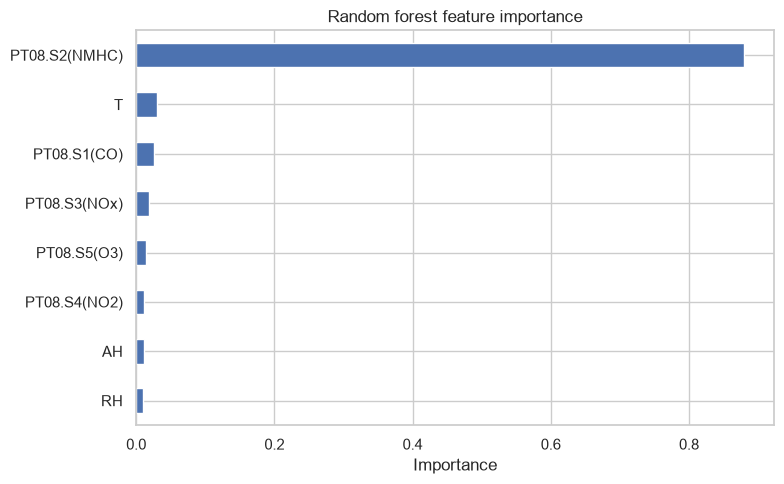

In [47]:
fitted_random_forest = model_pipelines["Random forest (200 trees)"].named_steps[
    "randomforestregressor"
]

feature_importance = pd.Series(
    fitted_random_forest.feature_importances_,
    index=features,
    name="importance"
).sort_values(ascending=False)

display(feature_importance.to_frame().round(4))

ax = feature_importance.sort_values().plot(kind="barh", figsize=(8, 5))
ax.set_title("Random forest feature importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 11. Time Series CV

The single chronological holdout gives only one comparison, so the ranking of the models could depend on that one period. Five expanding-window folds on the training period give five scores per model. Each fold trains on all earlier rows and validates on the next block, so a model never trains on the future. Ordinary random k-fold is not used, because neighbouring hours are nearly identical and the model would effectively see the answer.

In [48]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

tscv = TimeSeriesSplit(n_splits=5)

fold_r2 = {}
for name in ["Linear regression", "Random forest (200 trees)"]:
    scores = cross_validate(
        model_pipelines[name], X_train, Y_train,
        cv=tscv, scoring="r2"
    )
    fold_r2[name] = scores["test_score"]      # flip the sign: back to a plain MAE

fold_table = pd.DataFrame(fold_r2, index=[f"Fold {i}" for i in range(1, 6)])
fold_table.loc["Mean"] = fold_table.mean()
display(fold_table.round(3))

,Linear regression,Random forest (200 trees)
Fold 1,0.902,0.888
Fold 2,0.829,0.922
Fold 3,0.900,0.939
Fold 4,0.842,0.884
Fold 5,0.786,0.749
Mean,0.852,0.876


In [49]:
for i, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    print(f"Fold {i}: trained on {len(train_idx):,} rows | validated on "
          f"{X_train.index[val_idx].min().date()} to {X_train.index[val_idx].max().date()} "
          f"({len(val_idx):,} rows)")

Fold 1: trained on 980 rows | validated on 2004-05-01 to 2004-06-22 (979 rows)
Fold 2: trained on 1,959 rows | validated on 2004-06-22 to 2004-08-13 (979 rows)
Fold 3: trained on 2,938 rows | validated on 2004-08-13 to 2004-10-24 (979 rows)
Fold 4: trained on 3,917 rows | validated on 2004-10-24 to 2004-12-06 (979 rows)
Fold 5: trained on 4,896 rows | validated on 2004-12-06 to 2005-01-28 (979 rows)


## 12. Feature engineering: calendar features

The hourly pattern showed two clear rush-hour peaks, and traffic differs at weekends. The timestamp is known at prediction time, so three calendar features were added: `hour_sin` and `hour_cos` (the hour encoded as a point on a circle, so that hour 23 and hour 0 stay close together) and `is_weekend`.

In [50]:
def add_calendar_features(X):
    X = X.copy()
    hour = X.index.hour
    X["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    X["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    X["is_weekend"] = (X.index.day_of_week >= 5).astype(int)
    return X

X_train_cal = add_calendar_features(X_train)
display(X_train_cal)

r2_cal = {}
for name in ["Linear regression", "Random forest (200 trees)"]:
    scores = cross_validate(model_pipelines[name], X_train_cal, Y_train, cv=tscv, scoring="r2")
    r2_cal[name] = scores["test_score"]

cal_table = pd.DataFrame(r2_cal, index=[f"Fold {i}" for i in range(1, 6)])
cal_table.loc["Mean"] = cal_table.mean()
display(cal_table.round(3))

,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,hour_sin,hour_cos,is_weekend
Timestamp,,,,,,,,,,,
2004-03-10 18:00:00,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,0.7578,-1.000000,-1.836970e-16,0
2004-03-10 19:00:00,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,0.7255,-0.965926,2.588190e-01,0
2004-03-10 20:00:00,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,0.7502,-0.866025,5.000000e-01,0
2004-03-10 21:00:00,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,0.7867,-0.707107,7.071068e-01,0
2004-03-10 22:00:00,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,0.7888,-0.500000,8.660254e-01,0
...,...,...,...,...,...,...,...,...,...,...,...
2005-01-28 07:00:00,856.0,559.0,1138.0,810.0,556.0,4.1,47.4,0.3926,0.965926,-2.588190e-01,0
2005-01-28 08:00:00,1024.0,823.0,827.0,992.0,879.0,4.2,48.7,0.4073,0.866025,-5.000000e-01,0
2005-01-28 09:00:00,1050.0,909.0,742.0,1055.0,993.0,4.1,49.8,0.4117,0.707107,-7.071068e-01,0


,Linear regression,Random forest (200 trees)
Fold 1,0.907,0.891
Fold 2,0.787,0.928
Fold 3,0.892,0.946
Fold 4,0.847,0.896
Fold 5,0.788,0.758
Mean,0.844,0.884


## 13. Hyperparameter tuning

The random forest was tuned with `GridSearchCV` on the training period, using the same time-ordered folds. The grid covered `min_samples_leaf` (1, 3, 10) and `max_features` (0.33, 0.66, 1.0). The number of trees was kept at 200: more trees mainly reduce random noise and do not change what the forest can learn.

In [51]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "randomforestregressor__min_samples_leaf": [1, 3, 10],
    "randomforestregressor__max_features": [0.33, 0.66, 1.0],
}

search = GridSearchCV(model_pipelines["Random forest (200 trees)"],
                      param_grid, cv=tscv, scoring="r2")
search.fit(X_train_cal, Y_train)

results = pd.DataFrame(search.cv_results_)[[
    "param_randomforestregressor__min_samples_leaf",
    "param_randomforestregressor__max_features",
    "mean_test_score", "std_test_score"
]]

display(results.sort_values("mean_test_score", ascending=False).round(3))
print("Best settings:", search.best_params_)
print("Best CV R²:", round(search.best_score_, 3))

,param_randomforestregressor__min_samples_leaf,param_randomforestregressor__max_features,mean_test_score,std_test_score
4,3,0.66,0.886,0.060
7,3,1.00,0.885,0.063
3,1,0.66,0.884,0.064
6,1,1.00,0.884,0.066
8,10,1.00,0.881,0.056
5,10,0.66,0.878,0.054
0,1,0.33,0.874,0.063
1,3,0.33,0.873,0.059
2,10,0.33,0.862,0.052


Best settings: {'randomforestregressor__max_features': 0.66, 'randomforestregressor__min_samples_leaf': 3}
Best CV R²: 0.886


## 14. Final model and test evaluation

The final model was chosen using cross-validation on the training period only: the tuned random forest with calendar features (cross-validated R² 0.886, against 0.852 for linear regression). It is then scored once on the chronological test set.

Note that the test set was also used earlier for model comparison, error analysis and the feature ablation, so this is not a perfectly untouched holdout. The result is reported as it comes out, without changing the model afterwards.

In [52]:
X_test_cal = add_calendar_features(X_test)
final_model = search.best_estimator_      # tuned forest, already fitted on the full training period

pred_final = final_model.predict(X_test_cal)

results_rf_tuned = {}
results_rf_tuned["Random Forest Tuned"] = (regression_metrics(Y_test, pred_final))
results_rf_tuned_df = pd.DataFrame(results_rf_tuned).T

final_results = pd.concat([all_results, results_rf_tuned_df])
print(round(final_results,3))

                             MAE   RMSE     R2
Dummy (mean)               1.068  1.320 -0.030
Dummy (median)             1.000  1.301 -0.001
Linear regression          0.344  0.484  0.862
Random forest (200 trees)  0.368  0.538  0.829
Decision tree (depth 6)    0.411  0.642  0.756
Random Forest Tuned        0.322  0.476  0.866


## 15. Final Model

In [53]:
import joblib
from pathlib import Path

MODEL_DIR = Path("..") / "models"      # adjust to match your project folder
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(final_model, MODEL_DIR / "co_random_forest.joblib")

def predict_co(model, X_new):
    """X_new: the 8 sensor columns, with a datetime index. Returns predicted CO (mg/m³)."""
    X_new = add_calendar_features(X_new[features])
    return model.predict(X_new)

# Reload the saved file and check that it works on raw (8-column) data
loaded = joblib.load(MODEL_DIR / "co_random_forest.joblib")
print("Reloaded:", predict_co(loaded, X_test.head(3)).round(2))
print("Original:", predict_co(final_model, X_test.head(3)).round(2))
print("Actual:  ", Y_test.head(3).values)

Reloaded: [1.62 1.4  1.6 ]
Original: [1.62 1.4  1.6 ]
Actual:   [1.8 1.4 2.1]


## 15. Results, Findings and Limitations

All scores are on a chronological 80/20 holdout (the last 20% of hours, a later period than the training data).

| Model | MAE (mg/m³) | RMSE (mg/m³) | R² |
|---|---|---|---|
| Dummy (median) | 1.000 | 1.301 | -0.001 |
| Dummy (mean) | 1.068 | 1.320 | -0.030 |
| **Linear regression** | **0.344** | **0.484** | **0.862** |
| Random forest (200 trees) | 0.368 | 0.538 | 0.829 |
| Decision tree (depth 6) | 0.411 | 0.642 | 0.756 |
| **Random Forest Tuned** | **0.322** | **0.476** | **0.866** |

The final model is narrowly the best on all three metrics, but its margin over linear regression (R² +0.004) is far smaller than the fold-to-fold variation in cross-validation (about 0.06).

### Findings
- **The tuned random forest with calendar features scored best on the test set** (R² 0.866, MAE 0.322 mg/m³). Linear regression is very close (R² 0.862, MAE 0.344), and the difference is within the noise: in time-series cross-validation the forest won 3 of 5 folds, and linear regression won the others, so the ranking depends on the period. The two models should be treated as comparable. Linear regression has the advantage of simplicity and interpretability.
- **Both models cut the typical error by about two-thirds compared with the dummy baseline** (MAE 1.000 down to 0.322 for the final model).
- **Data preparation mattered.** About 330 hours had a reference CO value but no data from any cheap sensor. Imputing them gave every such row the same prediction. Dropping them raised linear regression's R² from 0.77 to 0.86 (the test period shifted slightly because rows were removed).
- **No single sensor is enough.** In the feature ablation (linear regression), `PT08.S2(NMHC)` alone reached R² 0.774 and `PT08.S1(CO)` alone 0.693, against 0.862 for all features. S1 and S5 are largely redundant, and weather alone has no skill (R² -0.026). Adding temperature and humidity to the five sensors raised R² only from 0.852 to 0.862.
- **Calendar features helped the forest slightly and not linear regression.** In cross-validation they improved all five forest folds (mean R² 0.876 to 0.884) and slightly lowered the linear model's mean (0.852 to 0.844).
- **Hyperparameter tuning made no meaningful difference.** The best setting scored 0.886 against 0.884 for the default settings, far less than the fold-to-fold spread.
- **Errors are small but systematic for linear regression:** it tends to over-predict at low CO and under-predict at high CO, and it can predict slightly negative values. Daily mean residuals sit slightly above zero with no clear drift from February to April, apart from two unexplained episodes (around 26 Feb and 11–13 Mar). The error analysis was done on linear regression and the untuned forest, before the final model was chosen.
- **Contrast with benzene.** In the benzene analysis, one sensor (`PT08.S2(NMHC)`) reproduced the target almost exactly. CO is a harder, more realistic problem, in which several sensors contribute and a simple linear model comes close to a tuned forest.

### Limitations
- The data covers about 13 months from one monitoring location, and the test period (about 2.5 months, winter into spring) is a single holdout. Neither model has seen a full year, so seasonal generalisation is untested.
- The test set was also used for model comparison, error analysis and the feature ablation, so the final score is not a perfectly untouched holdout.
- The margin between the final model and linear regression is small, and cross-validation folds are not independent (neighbouring hours are nearly identical).
- S1, S2 and S5 are strongly correlated, so ablation results and feature importance describe overlapping information, not separate effects.
- Weather was tested only as an additive term. Sensor-by-humidity and sensor-by-temperature interactions were not tested.
- The residual-over-time check covers a short window, so sensor drift cannot be ruled out. The two residual episodes were not investigated.
- No independent site or year has been used for external validation.
- This notebook does not include automated retraining, model serving, or production monitoring.

### Next experiments
1. Try a log-transformed target, or another way to avoid negative predictions, since errors grow with concentration.
2. Investigate the two residual episodes (around 26 Feb and 11–13 Mar).
3. Add automated tests for data schema, missingness, chronological ordering, and prediction output.
4. Move reusable code into `src/` modules and create a reproducible training entry point.